# Fast EIGER Correction Extraction: Aggregate Repeated Angles

This notebook retains the existing EIGER calibration model and fitting/validation routines while reducing repeated-angle scans to one summed frame per angle group. The configured example has 3,608 raw frames and 84 exact angle values; the default 0.001-degree grouping tolerance combines these into 41 angle groups.

> **Interpretation:** The default groups angles within 0.001 degrees of each group's lowest angle. Nearby angles are represented by their I0-weighted mean, so this is an approximation; set the tolerance to 0 for exact-only grouping. Raw counts and I0 are summed. A pixel is excluded from a group if any constituent value is nonfinite, negative, or saturated. Validation splits whole angle groups, so individual repeat anomalies cannot be assessed in this fast path. Group frame gains are diagnostics only, not transferable corrections.

Summation is used rather than a mean because the fitter expects raw counts with Poisson statistics and an I0 exposure normalization. The original source files are not changed. Set `USE_ANGLE_AGGREGATION=False` for the original per-frame path.

In [27]:
from pathlib import Path
import importlib
import json
import sys
import tempfile
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np

REPO_DIRECTORY = Path.cwd().resolve()
while REPO_DIRECTORY != REPO_DIRECTORY.parent and not (REPO_DIRECTORY / 'eiger_workflow.py').exists():
    REPO_DIRECTORY = REPO_DIRECTORY.parent
if not (REPO_DIRECTORY / 'eiger_workflow.py').exists():
    raise FileNotFoundError('Could not find eiger_workflow.py; launch Jupyter from the repository or a subdirectory.')

DATA_DIRECTORY = Path('/dls/i15-1/data/2026/cm44163-4')
OUTPUT_DIRECTORY = REPO_DIRECTORY / 'outputs'
OUTPUT_DIRECTORY.mkdir(exist_ok=True)
SCAN_PATH = DATA_DIRECTORY / 'i15-1-100599.nxs'
GEOMETRY_PATH = Path('/dls_sw/i15-1/software/daq_configuration/geometry/i15-1-100579_2026-10-15_20-37-08_eiger_goniometer_calibration.json')
CALIBRATION_OUTPUT = OUTPUT_DIRECTORY / f'{SCAN_PATH.stem}_detector_corrections_fast.h5'
TWO_THETA_XY_OUTPUT = OUTPUT_DIRECTORY / f'{SCAN_PATH.stem}_fast_source_effects_2theta.xy'

POLARIZATION_FACTOR = 0.95
SENSOR_DENSITY_G_CM3 = 6.2
FIT_Q_RANGE_NM = (200.0, 400.0)
FIT_BIN_COUNT = 800
FIT_ITERATIONS = 10
FIT_FRAME_GAINS = True
RUN_VALIDATION = True
WRITE_CALIBRATION = True
WRITE_XY = True
USE_ANGLE_AGGREGATION = True
ANGLE_TOLERANCE_DEG = 0.001
AGGREGATION_METHOD = 'sum'
RAW_SATURATION = 1e7
DETECTOR_PATH = None
MONITOR_PATH = None
METADATA_PATH = None
RUN_UNGROUPED_BENCHMARK = False  # Can be expensive in both time and memory.

assert SCAN_PATH.exists() and GEOMETRY_PATH.exists()
assert not CALIBRATION_OUTPUT.exists(), 'Choose a new CALIBRATION_OUTPUT; existing files are never overwritten.'
if WRITE_XY:
    assert not TWO_THETA_XY_OUTPUT.exists(), 'Choose a new TWO_THETA_XY_OUTPUT; existing files are never overwritten.'
assert AGGREGATION_METHOD == 'sum', 'Raw-count Poisson fitting requires summed counts; mean aggregation is not equivalent.'
assert ANGLE_TOLERANCE_DEG >= 0

print('Repository:', REPO_DIRECTORY)
print('Input scan:', SCAN_PATH)
print('Geometry:', GEOMETRY_PATH)
print('Calibration output:', CALIBRATION_OUTPUT)
print('2theta XY output:', TWO_THETA_XY_OUTPUT if WRITE_XY else 'disabled')
print('Aggregation enabled / method / angle tolerance:', USE_ANGLE_AGGREGATION, AGGREGATION_METHOD, ANGLE_TOLERANCE_DEG)

Repository: /dls/science/users/fer45166/eiger-correction
Input scan: /dls/i15-1/data/2026/cm44163-4/i15-1-100599.nxs
Geometry: /dls_sw/i15-1/software/daq_configuration/geometry/i15-1-100579_2026-10-15_20-37-08_eiger_goniometer_calibration.json
Calibration output: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100599_detector_corrections_fast.h5
2theta XY output: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100599_fast_source_effects_2theta.xy
Aggregation enabled / method / angle tolerance: True sum 0.001


## 1–3. Load Inputs, Parse Angle Metadata, and Detect Repeats

Load the NeXus metadata and companion detector/monitor/metadata files through the shared workflow module. The small angle index below avoids loading detector frames into memory just to inspect repetitions.

Raw scan summary: {'raw frames': 3608, 'unique exact angles': 76, 'duplicate frames beyond first': 3532, 'maximum repeats at one angle': 88, 'angles repeated more than once': 71}
Angle range (degrees): 0.0 80.00003035659999
Repeat-count distribution (frames per angle -> number of angles): {1: 5, 2: 18, 3: 6, 4: 3, 6: 3, 79: 1, 82: 4, 84: 4, 85: 3, 86: 14, 87: 3, 88: 12}
First source frame -> angle/group/repeat count:
0 0.0 0 88
1 0.0 0 88
2 0.0 0 88
3 0.0 0 88
4 0.0 0 88
5 0.0 0 88
6 0.0 0 88
7 0.0 0 88
8 0.0 0 88
9 0.0 0 88
10 0.0 0 88
11 0.0 0 88


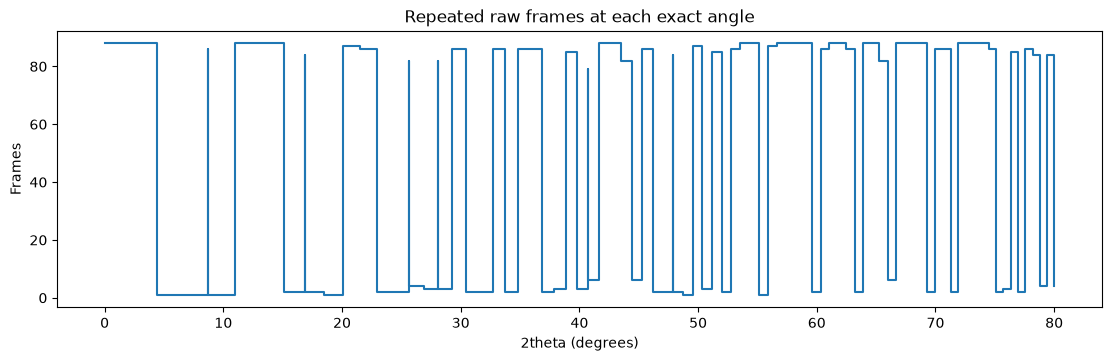

In [28]:
if str(REPO_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(REPO_DIRECTORY))
import eiger_workflow as workflow
importlib.reload(workflow)

raw_scan = workflow.load_scan(SCAN_PATH, DETECTOR_PATH, MONITOR_PATH, METADATA_PATH)
unique_raw_angles, raw_inverse, raw_repeats = np.unique(raw_scan.angles, return_inverse=True, return_counts=True)
repeat_summary = {
    'raw frames': len(raw_scan.angles),
    'unique exact angles': len(unique_raw_angles),
    'duplicate frames beyond first': int(len(raw_scan.angles) - len(unique_raw_angles)),
    'maximum repeats at one angle': int(raw_repeats.max()),
    'angles repeated more than once': int(np.count_nonzero(raw_repeats > 1)),
}
print('Raw scan summary:', repeat_summary)
print('Angle range (degrees):', float(raw_scan.angles.min()), float(raw_scan.angles.max()))
print('Repeat-count distribution (frames per angle -> number of angles):', {
    int(count): int(number) for count, number in zip(*np.unique(raw_repeats, return_counts=True))
})
print('First source frame -> angle/group/repeat count:')
for frame_index in range(min(12, len(raw_scan.angles))):
    group_index = int(raw_inverse[frame_index])
    print(frame_index, float(raw_scan.angles[frame_index]), group_index, int(raw_repeats[group_index]))

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.step(unique_raw_angles, raw_repeats, where='mid')
ax.set(title='Repeated raw frames at each exact angle', xlabel='2theta (degrees)', ylabel='Frames')
plt.show()

## 4–6. Combine Matching Frames and Rebuild the Reduced Processing Dataset

The reusable helper streams frames into a temporary HDF5 dataset, summing counts and I0 per angle group. For every pixel, any invalid member causes that group's pixel to be masked, rather than silently treating missing data as zero. Downstream fitting continues to use the same `Scan`, cache, fitting, and validation interfaces.

In [29]:
aggregation_seconds = 0.0
if USE_ANGLE_AGGREGATION:
    working_directory = tempfile.TemporaryDirectory(dir=OUTPUT_DIRECTORY, prefix='.eiger_fast_')
    AGGREGATED_DATA_PATH = Path(working_directory.name) / 'angle_aggregated_frames.h5'
    aggregation_start = time.perf_counter()
    analysis_scan, frame_groups = workflow.aggregate_equal_angle_frames(
        raw_scan, AGGREGATED_DATA_PATH, saturation=RAW_SATURATION,
        angle_tolerance=ANGLE_TOLERANCE_DEG,
    )
    aggregation_seconds = time.perf_counter() - aggregation_start
else:
    analysis_scan = raw_scan
    frame_groups = [np.array([index], dtype=int) for index in range(len(raw_scan.angles))]
    working_directory = None
    AGGREGATED_DATA_PATH = None

print('Reduced frames:', len(analysis_scan.angles))
print('Frame reduction factor:', len(raw_scan.angles) / len(analysis_scan.angles))
group_angle_spreads = np.array([np.ptp(raw_scan.angles[members]) for members in frame_groups])
print('Groups combining distinct exact angle values:', int(np.count_nonzero(group_angle_spreads > 0)))
print('Maximum source-angle span within a group (degrees):', float(group_angle_spreads.max()))
print('Aggregation elapsed (s):', aggregation_seconds)
print('Reduced detector dataset shape:', (len(analysis_scan.angles), *analysis_scan.shape))
print('I0 aggregation check:', bool(np.all(analysis_scan.i0 > 0)))
if AGGREGATED_DATA_PATH is not None:
    with h5py.File(AGGREGATED_DATA_PATH, 'r') as grouped_file:
        np.testing.assert_equal(grouped_file['data'].shape, (len(frame_groups), *raw_scan.shape))
        np.testing.assert_equal(grouped_file['source_frame_indices'].shape[0], len(raw_scan.angles))
        print('Temporary grouped HDF5:', AGGREGATED_DATA_PATH)

# Check one of the smallest repeated groups without stacking all its raw images.
check_group_index = min(
    (i for i, members in enumerate(frame_groups) if len(members) > 1),
    key=lambda i: len(frame_groups[i]), default=None,
)
if check_group_index is not None and AGGREGATED_DATA_PATH is not None:
    members = frame_groups[check_group_index]
    expected = np.zeros(raw_scan.shape, dtype=float)
    invalid_any = np.zeros(raw_scan.shape, dtype=bool)
    with h5py.File(raw_scan.detector_path, 'r') as raw_file, h5py.File(AGGREGATED_DATA_PATH, 'r') as grouped_file:
        for frame_index in members:
            raw_frame = np.asarray(raw_file[raw_scan.detector_dataset][int(frame_index)], dtype=float)
            invalid = ~np.isfinite(raw_frame) | (raw_frame < 0) | (raw_frame >= RAW_SATURATION)
            invalid_any |= invalid
            expected += np.where(invalid, 0.0, raw_frame)
        expected[invalid_any] = np.nan
        np.testing.assert_allclose(grouped_file['data'][check_group_index], expected, rtol=0, atol=0, equal_nan=True)
        np.testing.assert_allclose(analysis_scan.i0[check_group_index], raw_scan.i0[members].sum(), rtol=1e-14)
    angle_spread = float(np.ptp(raw_scan.angles[members]))
    print('Sample aggregate raw-count and summed-I0 checks passed for', len(members), 'frames; angle spread (degrees):', angle_spread)
else:
    print('No repeated group available for the sample check; dataset shape and I0 checks passed.')

Reduced frames: 41
Frame reduction factor: 88.0
Groups combining distinct exact angle values: 29
Maximum source-angle span within a group (degrees): 0.00011098460000269483
Aggregation elapsed (s): 16.42608820553869
Reduced detector dataset shape: (41, 512, 1028)
I0 aggregation check: True
Temporary grouped HDF5: /dls/science/users/fer45166/eiger-correction/outputs/.eiger_fast_rkpk8vth/angle_aggregated_frames.h5
Sample aggregate raw-count and summed-I0 checks passed for 88 frames; angle spread (degrees): 0.0


In [30]:
geometry_config = json.loads(GEOMETRY_PATH.read_text())
physical_model = workflow.PhysicalModel(geometry_config, analysis_scan, POLARIZATION_FACTOR, SENSOR_DENSITY_G_CM3)
geometry_checks = physical_model.vertical_check()
boundary_mask, sensor_ids = workflow.detector_layout(analysis_scan.shape)
base_mask = analysis_scan.native_mask | boundary_mask
sensor_ids[base_mask] = -1
workflow.constant_pattern_check(physical_model, base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT)

fit_settings = {
    'q_range': list(FIT_Q_RANGE_NM), 'npt': FIT_BIN_COUNT, 'iterations': FIT_ITERATIONS,
    'fit_frame_gains': FIT_FRAME_GAINS, 'fractional_floor': 0.003, 'reject_z': 5.0,
    'minimum_observations': 8, 'shrink_weight': 300.0, 'frame_prior_sigma': 0.01,
    'angle_aggregation': {
        'enabled': bool(USE_ANGLE_AGGREGATION), 'method': AGGREGATION_METHOD,
        'angle_tolerance_deg': float(ANGLE_TOLERANCE_DEG),
        'source_frame_count': int(len(raw_scan.angles)),
        'analysis_position_count': int(len(analysis_scan.angles)),
        'group_sizes': [int(len(members)) for members in frame_groups],
    },
}
cache_saturation = np.inf if USE_ANGLE_AGGREGATION else RAW_SATURATION
fit_options = {key: value for key, value in fit_settings.items() if key not in {'q_range', 'angle_aggregation'}}

print('Frames / detector shape used for fitting:', len(analysis_scan.angles), analysis_scan.shape)
print('Angle range:', float(analysis_scan.angles.min()), float(analysis_scan.angles.max()))
print('Aggregated I0 range:', float(analysis_scan.i0.min()), float(analysis_scan.i0.max()))
print('Geometry checks:', geometry_checks)
print('Native / boundary-combined mask:', int(analysis_scan.native_mask.sum()), int(base_mask.sum()))
print('CdTe normal transmission / absorbed fraction:', physical_model.transmission, physical_model.efficiency)
print('Constant-pattern physical-correction check passed.')

Frames / detector shape used for fitting: 41 (512, 1028)
Angle range: 0.0 79.99997738687412
Aggregated I0 range: 0.46144229004086484 0.4674656810924362
Geometry checks: [{'angle_deg': 20, 'vertical_fraction': 0.999997428583921, 'chi_deg': 90.10383780797738}, {'angle_deg': 40, 'vertical_fraction': 0.9999993118660422, 'chi_deg': 90.05370294225928}, {'angle_deg': 60, 'vertical_fraction': 0.999999629778898, 'chi_deg': 90.03938685222737}]
Native / boundary-combined mask: 1057 17323
CdTe normal transmission / absorbed fraction: 0.20769048111688532 0.7923095188831146
Constant-pattern physical-correction check passed.


In [31]:
# Compare separate and summed integrations for a tiny representative sample.
# Prefer a tolerance-merged group that actually contributes in the fitting q range.
tolerance_group_index = None
for i, group in enumerate(frame_groups):
    if np.ptp(raw_scan.angles[group]) <= 0:
        continue
    representative_angle = float(np.average(raw_scan.angles[group], weights=raw_scan.i0[group]))
    q_pixels = physical_model.arrays(representative_angle)[1]
    q_support = (~base_mask) & (q_pixels >= FIT_Q_RANGE_NM[0]) & (q_pixels < FIT_Q_RANGE_NM[1])
    if np.count_nonzero(q_support) >= 100:
        tolerance_group_index = i
        break

if USE_ANGLE_AGGREGATION and tolerance_group_index is not None:
    tolerance_members = frame_groups[tolerance_group_index]
    _, first_positions = np.unique(raw_scan.angles[tolerance_members], return_index=True)
    sample_indices = tolerance_members[np.sort(first_positions)]
elif USE_ANGLE_AGGREGATION and check_group_index is not None and len(frame_groups[check_group_index]) <= 4:
    sample_indices = frame_groups[check_group_index]
else:
    sample_indices = np.array([], dtype=int)

if len(sample_indices) > 1:
    with h5py.File(raw_scan.detector_path, 'r') as raw_file:
        raw_sample_frames = [
            np.asarray(raw_file[raw_scan.detector_dataset][int(frame_index)], dtype=float)
            for frame_index in sample_indices
        ]
    raw_sample_stack = np.stack(raw_sample_frames)
    invalid_any = np.any(
        ~np.isfinite(raw_sample_stack) | (raw_sample_stack < 0) | (raw_sample_stack >= RAW_SATURATION),
        axis=0,
    )
    common_mask = base_mask | invalid_any
    sample_counts = np.where(invalid_any, 0.0, raw_sample_stack).sum(axis=0)
    sample_counts[invalid_any] = np.nan
    sample_i0 = float(raw_scan.i0[sample_indices].sum())
    sample_angle = float(np.average(raw_scan.angles[sample_indices], weights=raw_scan.i0[sample_indices]))
    per_frame_results = {
        int(frame_index): workflow.integrate_frame(
            physical_model, raw_sample_frames[position], raw_scan.angles[int(frame_index)],
            raw_scan.i0[int(frame_index)], common_mask, np.ones(analysis_scan.shape),
            FIT_BIN_COUNT, FIT_Q_RANGE_NM, saturation=RAW_SATURATION,
        )
        for position, frame_index in enumerate(sample_indices)
    }
    summed_result = workflow.integrate_frame(
        physical_model, sample_counts, sample_angle, sample_i0,
        common_mask, np.ones(analysis_scan.shape), FIT_BIN_COUNT, FIT_Q_RANGE_NM,
        saturation=np.inf,
    )
    separate_merged = workflow.merge_results(per_frame_results)
    separate_intensity = separate_merged['intensity']
    valid_bins = (summed_result.count > 0) & (separate_merged['accumulators'][3] > 0)
    valid_bins &= np.isfinite(summed_result.intensity) & np.isfinite(separate_intensity)
    valid_bins &= (summed_result.intensity > 0) & (separate_intensity > 0)
    relative_difference = np.abs(summed_result.intensity[valid_bins] - separate_intensity[valid_bins]) / separate_intensity[valid_bins]
    print('Sample separate-vs-summed integration; frames:', len(sample_indices), 'angle span (deg):', float(np.ptp(raw_scan.angles[sample_indices])))
    if relative_difference.size:
        print('Relative intensity difference, median / 95th percentile / max (%):', 100 * np.percentile(relative_difference, [50, 95, 100]))
    else:
        print('No common supported q bins in the sample integration comparison.')
else:
    print('Integration comparison skipped: no tolerance-merged group contributes in the fitting q range.')

Sample separate-vs-summed integration; frames: 2 angle span (deg): 5.549229999957106e-05
Relative intensity difference, median / 95th percentile / max (%): [0.000206   0.00211071 0.04606766]


## Run the Existing Fit and Held-Out Validation on the Reduced Scan

The fitting and integration logic is the same as the original notebook. The alternating-position validation now holds out complete angle groups; group-level frame gains remain source-only diagnostics.

Cache construction time (s): 2.063190871849656
Cached contributing angle groups: 29
Cached observations: 9601740
Sparse cache memory (MiB): 128.19705963134766

 Even angle groups train / odd test
{'iteration': 1, 'rejected_percent': np.float64(0.0), 'max_log_gain_change': 0.16517068831888437}
{'iteration': 2, 'rejected_percent': np.float64(0.0), 'max_log_gain_change': 0.013209166779068568}
{'iteration': 3, 'rejected_percent': np.float64(0.013151712074062452), 'max_log_gain_change': 0.15350874470971082}
{'iteration': 4, 'rejected_percent': np.float64(0.014816485754323521), 'max_log_gain_change': 0.00119138373079547}
{'iteration': 5, 'rejected_percent': np.float64(0.014837295425326785), 'max_log_gain_change': 0.0033813282072268323}
{'iteration': 6, 'rejected_percent': np.float64(0.014837295425326785), 'max_log_gain_change': 0.00020759065541566674}
{'iteration': 7, 'rejected_percent': np.float64(0.014837295425326785), 'max_log_gain_change': 9.21653678972803e-05}
{'iteration': 8, 'rejected

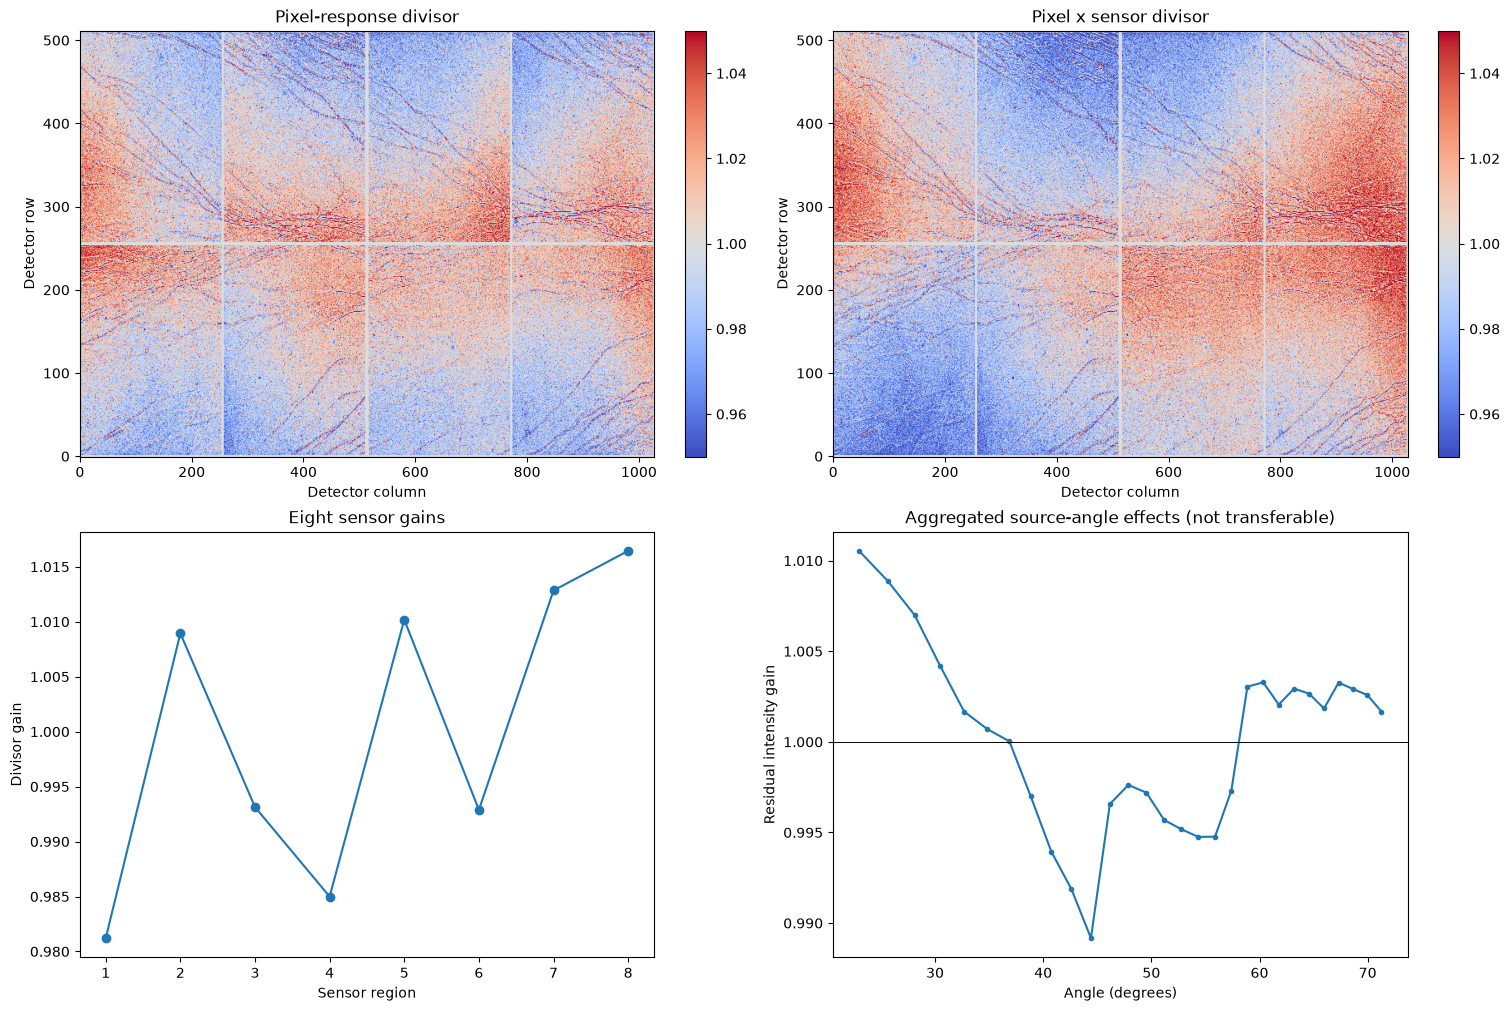

In [32]:
cache_start = time.perf_counter()
cache = workflow.build_cache(
    analysis_scan, physical_model, base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT,
    saturation=cache_saturation,
)
cache_seconds = time.perf_counter() - cache_start
contributing_indices = np.array(sorted(cache), dtype=int)
print('Cache construction time (s):', cache_seconds)
print('Cached contributing angle groups:', len(contributing_indices))
print('Cached observations:', sum(len(frame['pixels']) for frame in cache.values()))
cache_bytes = sum(array.nbytes for frame in cache.values() for array in frame.values())
print('Sparse cache memory (MiB):', cache_bytes / 2**20)

validation_reports = []
validation_fits = []
if RUN_VALIDATION:
    folds = (
        ('Even angle groups train / odd test', contributing_indices[contributing_indices % 2 == 0], contributing_indices[contributing_indices % 2 == 1]),
        ('Odd angle groups train / even test', contributing_indices[contributing_indices % 2 == 1], contributing_indices[contributing_indices % 2 == 0]),
    )
    for fold_name, train_indices, test_indices in folds:
        print('\n', fold_name)
        fold_fit = workflow.fit_response(cache, train_indices, sensor_ids, len(analysis_scan.angles), **fit_options)
        validation = workflow.validate_response(
            analysis_scan, physical_model, cache, fold_fit, test_indices,
            base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT, saturation=cache_saturation,
        )
        validation_reports.append({'fold': fold_name, 'metrics': validation['summary'], 'frame_gain_checks': validation['frame_rows']})
        validation_fits.append(fold_fit)
        for row in validation['summary']:
            print(row)
    fold_sensor_difference = 100 * np.sqrt(np.mean((np.log(validation_fits[0]['sensor_gains']) - np.log(validation_fits[1]['sensor_gains']))**2))
    print('Sensor log-gain RMS difference between folds (%):', fold_sensor_difference)
else:
    print('WARNING: independent angle-group validation is disabled.')

print('\nFull grouped-scan fit')
calibration_fit = workflow.fit_response(cache, contributing_indices, sensor_ids, len(analysis_scan.angles), **fit_options)
print('Sensor gains:', calibration_fit['sensor_gains'])
print('Persistent bad-pixel candidates:', int(calibration_fit['bad_pixel_mask'].sum()))
print('Largest group-level frame gains:')
for index in sorted(contributing_indices, key=lambda index: abs(np.log(calibration_fit['frame_gains'][index])), reverse=True)[:8]:
    print(f'angle={analysis_scan.angles[index]:.6f}; summed I0={analysis_scan.i0[index]:.8f}; residual gain={calibration_fit["frame_gains"][index]:.6f}')

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for plot_axis, field, title in ((axes[0, 0], 'pixel_divisor', 'Pixel-response divisor'), (axes[0, 1], 'combined_divisor', 'Pixel x sensor divisor')):
    image = plot_axis.imshow(calibration_fit[field], origin='lower', aspect='auto', cmap='coolwarm', vmin=0.95, vmax=1.05)
    plot_axis.set(title=title, xlabel='Detector column', ylabel='Detector row')
    fig.colorbar(image, ax=plot_axis)
axes[1, 0].plot(np.arange(1, 9), calibration_fit['sensor_gains'], marker='o')
axes[1, 0].set(title='Eight sensor gains', xlabel='Sensor region', ylabel='Divisor gain')
axes[1, 1].plot(analysis_scan.angles[contributing_indices], calibration_fit['frame_gains'][contributing_indices], marker='.')
axes[1, 1].axhline(1, color='black', linewidth=0.7)
axes[1, 1].set(title='Aggregated source-angle effects (not transferable)', xlabel='Angle (degrees)', ylabel='Residual intensity gain')
plt.show()

## 7. Benchmark Runtime and Memory

The reduced-path timing includes raw-frame aggregation plus cache construction. The ungrouped benchmark is opt-in because caching every raw frame can require substantial memory; when enabled it measures the same cache-building stage with the original scan and reports observed speedup and sparse-cache bytes.

In [33]:
reduced_path_seconds = aggregation_seconds + cache_seconds
reduced_cache_mib = cache_bytes / 2**20
print('Reduced-path elapsed (aggregation + cache, s):', reduced_path_seconds)
print('Reduced-path sparse cache (MiB):', reduced_cache_mib)
print('Input-to-fit-position reduction:', f'{len(raw_scan.angles)} -> {len(analysis_scan.angles)}', f'({100 * (1 - len(analysis_scan.angles) / len(raw_scan.angles)):.1f}% fewer positions)')

if RUN_UNGROUPED_BENCHMARK:
    import gc
    baseline_start = time.perf_counter()
    baseline_cache = workflow.build_cache(
        raw_scan, physical_model, base_mask, FIT_Q_RANGE_NM, FIT_BIN_COUNT,
        saturation=RAW_SATURATION,
    )
    baseline_seconds = time.perf_counter() - baseline_start
    baseline_bytes = sum(array.nbytes for frame in baseline_cache.values() for array in frame.values())
    print('Ungrouped cache elapsed (s):', baseline_seconds)
    print('Ungrouped sparse cache (MiB):', baseline_bytes / 2**20)
    print('Measured end-to-end cache-path speedup:', baseline_seconds / reduced_path_seconds if reduced_path_seconds else np.nan)
    del baseline_cache
    gc.collect()
else:
    print('Ungrouped timing skipped. Set RUN_UNGROUPED_BENCHMARK=True to measure it; this can use considerably more RAM.')

print('Cache sizes can differ because aggregation intentionally makes each angle group one observation; individual-repeat outlier diagnostics are not retained.')

Reduced-path elapsed (aggregation + cache, s): 18.489279077388346
Reduced-path sparse cache (MiB): 128.19705963134766
Input-to-fit-position reduction: 3608 -> 41 (98.9% fewer positions)
Ungrouped timing skipped. Set RUN_UNGROUPED_BENCHMARK=True to measure it; this can use considerably more RAM.
Cache sizes can differ because aggregation intentionally makes each angle group one observation; individual-repeat outlier diagnostics are not retained.


## 8–9. Save the Calibration, Export a Source XY, and Reuse the Fast Path

The fast path is implemented as `workflow.aggregate_equal_angle_frames()` and is controlled by the aggregation and fallback settings above. After fitting, the notebook also runs the processing integrator on the aggregated source scan and exports a 2theta `.xy` file. For this same source scan only, it explicitly applies the fitted group-level source-angle gains as a best-effort normalization; these gains must not be used on another scan. Full-range 2theta integration extends beyond the fitting q range and should be treated as extrapolation. The temporary aggregated detector file is removed after export; raw source files and the original extraction notebook remain unchanged.

In [34]:
calibration_file_written = None
try:
    if WRITE_CALIBRATION:
        calibration_file_written = workflow.save_calibration(
            CALIBRATION_OUTPUT, analysis_scan, physical_model, calibration_fit, base_mask,
            sensor_ids, fit_settings, validation_reports,
        )
        saved = workflow.load_calibration(calibration_file_written)
        np.testing.assert_array_equal(saved['combined_divisor'], calibration_fit['combined_divisor'])
        print('Created and read-back verified calibration:', calibration_file_written)
    else:
        saved = {
            'fit_settings': fit_settings,
            'source_scan': str(analysis_scan.path),
            'frame_angles': analysis_scan.angles,
            'frame_i0': analysis_scan.i0,
            'frame_gains': calibration_fit['frame_gains'],
            'combined_divisor': calibration_fit['combined_divisor'],
            'base_mask': base_mask,
            'bad_pixel_mask': calibration_fit['bad_pixel_mask'],
        }
        print('Calibration export disabled; using in-memory fit for source integration.')

    if WRITE_XY:
        processed_for_xy = workflow.process_scan(
            analysis_scan, saved, physical_model,
            q_range=FIT_Q_RANGE_NM, q_npt=FIT_BIN_COUNT, theta_npt=1000,
            apply_calibration_frame_gains=True,
            allow_extrapolation=True,
            saturation=cache_saturation,
        )
        np.testing.assert_array_equal(processed_for_xy['frame_gains'], calibration_fit['frame_gains'])
        theta_group = processed_for_xy['groups']['merged_2theta']
        supported = (theta_group['accumulators'][1] > 0)
        supported &= np.isfinite(theta_group['axis']) & np.isfinite(theta_group['intensity'])
        xy_data = np.column_stack((theta_group['axis'][supported], theta_group['intensity'][supported]))
        assert xy_data.size > 0, 'No supported 2theta bins are available to export.'
        with TWO_THETA_XY_OUTPUT.open('x', encoding='ascii') as xy_file:
            np.savetxt(xy_file, xy_data, fmt='%.10g', header='2theta_deg intensity')
        print('Created best-effort source-scan 2theta XY:', TWO_THETA_XY_OUTPUT)
        print('Applied fitted group-level source-angle gains:', len(processed_for_xy['frame_gains']))
        print('Exported supported bins:', len(xy_data))
        print('Full-range 2theta bins outside the detector-fit q range are extrapolated.')
    else:
        print('XY export disabled.')
finally:
    if working_directory is not None:
        working_directory.cleanup()
        print('Removed temporary aggregated detector data.')

Created and read-back verified calibration: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100599_detector_corrections_fast.h5


Created best-effort source-scan 2theta XY: /dls/science/users/fer45166/eiger-correction/outputs/i15-1-100599_fast_source_effects_2theta.xy
Applied fitted group-level source-angle gains: 41
Exported supported bins: 1000
Full-range 2theta bins outside the detector-fit q range are extrapolated.
Removed temporary aggregated detector data.
